In [372]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from rich import print
from graphviz import Digraph

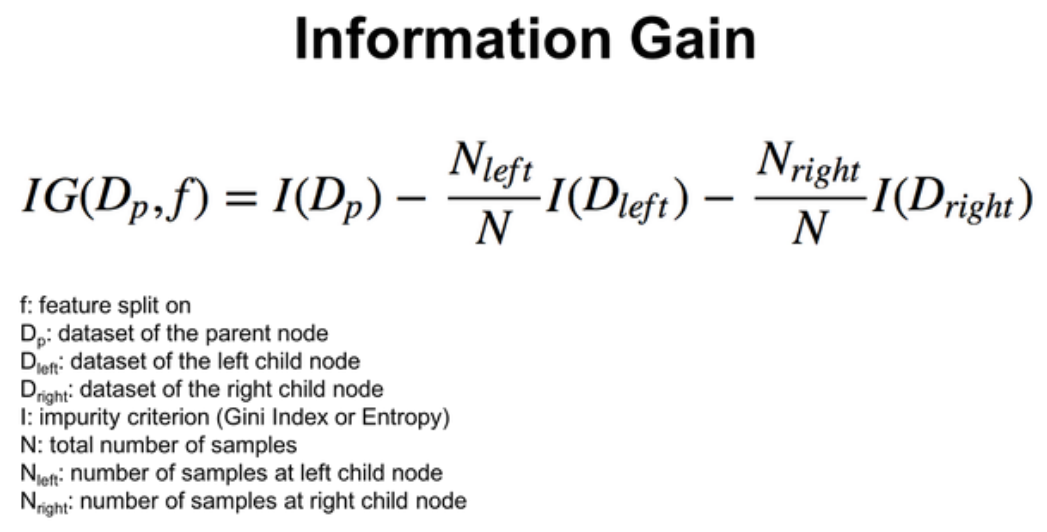

In [373]:
from math import log2


def FindGain(X: pd.DataFrame, target_variable="survived"):
    num = X.select_dtypes(exclude=["object", "bool", "category"])
    cat = X.select_dtypes(include=["object", "bool", "category"])
    prob_yes = X[X["survived"] == 1].shape[0] / X.shape[0]
    prob_no = 1 - prob_yes
    entropy_parent = -(prob_yes * log2(prob_yes) + prob_no * log2(prob_no))

    cat_splits = {}
    information_gain = {}
    for _ in cat:
        if _ == target_variable:
            continue
        unique_values = X[_].unique()
        for __ in unique_values:
            cat_splits[_] = X[X[_] == __]

    for i in cat_splits.keys():
        value_counts = cat_splits[i].value_counts(target_variable)
        count_yes = value_counts.get(1, 0)
        total_count = cat_splits[i].shape[0]

        prob_yes_child = count_yes / total_count if total_count > 0 else 0
        prob_no_child = 1 - prob_yes_child

        entropy_child = 0
        if 0 < prob_yes_child < 1:
            entropy_child = -(
                prob_yes_child * np.log2(prob_yes_child)
                + prob_no_child * np.log2(prob_no_child)
            )

        weighted_avg = cat_splits[i].shape[0] / cat.shape[0]
        gain = entropy_parent - (weighted_avg * entropy_child)
        information_gain[i] = gain

    return information_gain


def split_data_by_feature(data, feature):
    return {
        val: data[data[feature] == val].reset_index(drop=True)
        for val in data[feature].unique()
    }


def get_best_split(data, target="survived"):
    gain_dict = FindGain(data, target_variable=target)
    if not gain_dict:
        return None, {}
    best_feature = max(gain_dict, key=gain_dict.get)
    return best_feature, gain_dict


def visualize_tree(
    data, target="survived", dot=None, parent=None, edge_label=None, node_id=[0]
):
    if dot is None:
        dot = Digraph()
        dot.attr("node", shape="box", style="filled", color="lightblue2")

    # Base case: if pure or no feature left
    unique_classes = data[target].unique()
    if len(unique_classes) == 1:
        label = f"Leaf: {unique_classes[0]}"
        dot.node(str(node_id[0]), label, color="lightgreen")
        if parent is not None:
            dot.edge(parent, str(node_id[0]), label=edge_label)
        node_id[0] += 1
        return dot

    if data.shape[1] == 1:  # only target left
        majority = data[target].mode()[0]
        label = f"Leaf (majority): {majority}"
        dot.node(str(node_id[0]), label, color="orange")
        if parent is not None:
            dot.edge(parent, str(node_id[0]), label=edge_label)
        node_id[0] += 1
        return dot

    # Recursive case
    best_feat, gain_dict = get_best_split(data, target)
    if best_feat is None:
        majority = data[target].mode()[0]
        label = f"Leaf (default): {majority}"
        dot.node(str(node_id[0]), label, color="yellow")
        if parent is not None:
            dot.edge(parent, str(node_id[0]), label=edge_label)
        node_id[0] += 1
        return dot

    prob_yes = data[data[target] == 1].shape[0] / data.shape[0]
    prob_no = 1 - prob_yes
    entropy_parent = (
        -(prob_yes * log2(prob_yes) + prob_no * log2(prob_no))
        if 0 < prob_yes < 1
        else 0
    )

    label = f"{best_feat}\nIG={gain_dict[best_feat]:.3f}\nEntropy={entropy_parent:.3f}"
    curr_id = str(node_id[0])
    dot.node(curr_id, label)
    if parent is not None:
        dot.edge(parent, curr_id, label=edge_label)
    node_id[0] += 1

    splits = split_data_by_feature(data, best_feat)
    for val, subset in splits.items():
        subset = subset.drop(columns=[best_feat])
        visualize_tree(
            subset,
            target=target,
            dot=dot,
            parent=curr_id,
            edge_label=str(val),
            node_id=node_id,
        )

    return dot

In [374]:
df = sns.load_dataset("titanic")

In [375]:
df.dropna(inplace=True)

In [376]:
df = df.drop(columns=["alive", "embark_town"], axis=1)

In [377]:
dot = visualize_tree(df)
dot.render("tree_diagram", format="png", cleanup=True)
dot.view()

'tree_diagram.pdf'

In [378]:
sorted(FindGain(df).items(), key=lambda x: x[1], reverse=True)

[('embarked', np.float64(0.8978758266323493)),
 ('who', np.float64(0.8646232522871629)),
 ('deck', np.float64(0.8517095444861568)),
 ('class', np.float64(0.8493652693614129)),
 ('alone', np.float64(0.49690629274012776)),
 ('adult_male', np.float64(0.44742218133301814)),
 ('sex', np.float64(0.3984695861020914))]

In [379]:
# As there is only one value in final split, this means it is leaf node and the entropy is 0 (Zero) in this case.

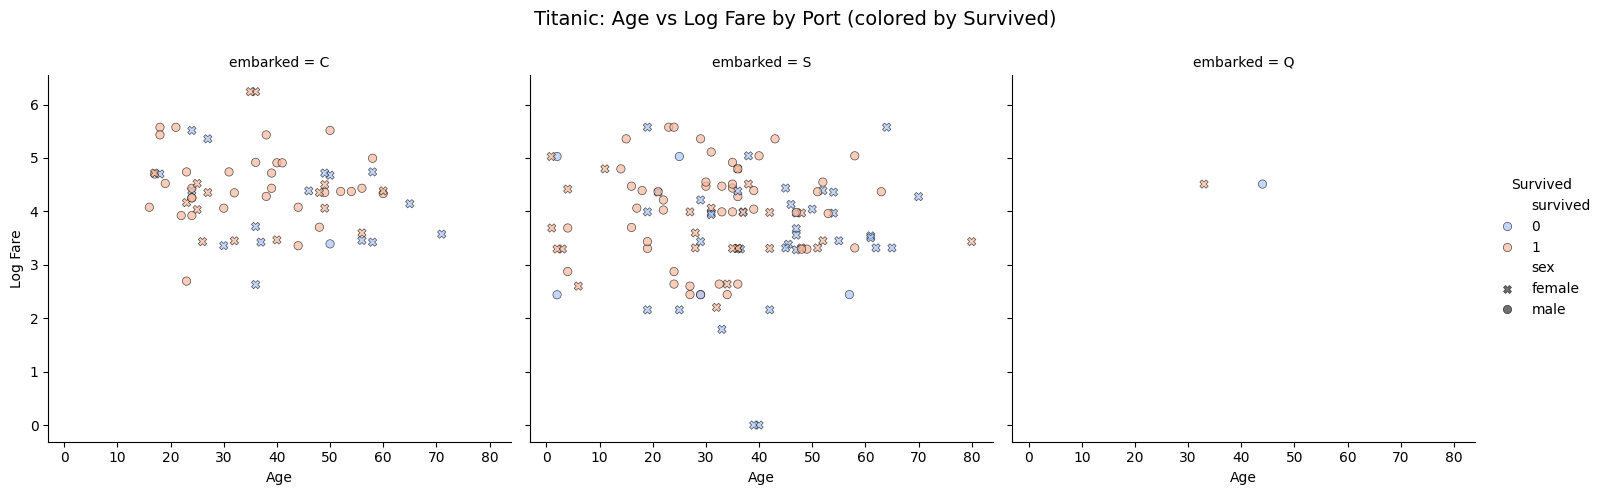

In [380]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Preprocess
df["log_fare"] = np.log1p(df["fare"])
df["sex"] = df["sex"].astype(str)
df["embarked"] = df["embarked"].astype(str)

# FacetGrid without hue parameter
g = sns.FacetGrid(
    df,
    col="embarked",
    height=5,
    legend_out=True,
)

# Map with hue in scatterplot
g.map_dataframe(
    sns.scatterplot,
    x="age",
    y="log_fare",
    hue="survived",
    style="sex",
    alpha=0.7,
    edgecolor="k",
    palette="coolwarm",
    hue_order=[0, 1],
)

# Move legend and adjust title
g.add_legend(title="Survived")
g.figure.subplots_adjust(top=0.85)
g.figure.suptitle("Titanic: Age vs Log Fare by Port (colored by Survived)", fontsize=14)

g.set_axis_labels("Age", "Log Fare")
plt.savefig("DecisionTree.png")
plt.show()